In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)
print("TensorFlow is available:", bool(tf.executing_eagerly()))

TensorFlow version: 2.21.0
TensorFlow is available: True


In [2]:
(x_train_full, y_train_full_raw), (x_test_raw, y_test_raw) = keras.datasets.cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full_raw.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test_raw.shape)
print("One image shape:", x_train_full[0].shape)
print("Pixel data type:", x_train_full.dtype)

# Remove the unnecessary single-column axis from the labels.
y_train_full = y_train_full_raw.reshape(-1)
y_test = y_test_raw.reshape(-1)
print("Reshaped training labels:", y_train_full.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1465s 9us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)
One image shape: (32, 32, 3)
Pixel data type: uint8
Reshaped training labels: (50000,)


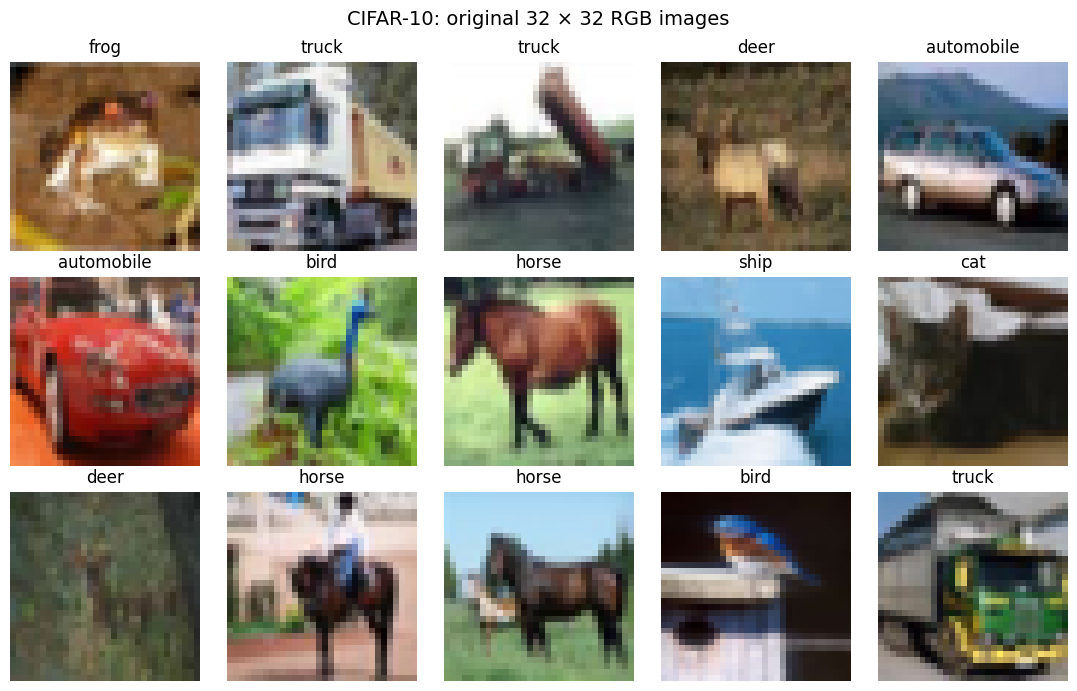

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i])
    ax.set_title(class_names[int(y_train_full[i])])
    ax.axis("off")
fig.suptitle("CIFAR-10: original 32 × 32 RGB images", fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
image_rgb = x_train_full[0]
row, col = 16, 16
red = image_rgb[:, :, 0]
green = image_rgb[:, :, 1]
blue = image_rgb[:, :, 2]
reconstructed = np.stack([red, green, blue], axis=-1)

print("RGB image shape:", image_rgb.shape)
print("Red-channel matrix:", red.shape)
print("One RGB pixel [R, G, B]:", image_rgb[row, col].tolist())
print("Reconstructed image identical:", np.array_equal(image_rgb, reconstructed))

RGB image shape: (32, 32, 3)
Red-channel matrix: (32, 32)
One RGB pixel [R, G, B]: [245, 237, 226]
Reconstructed image identical: True


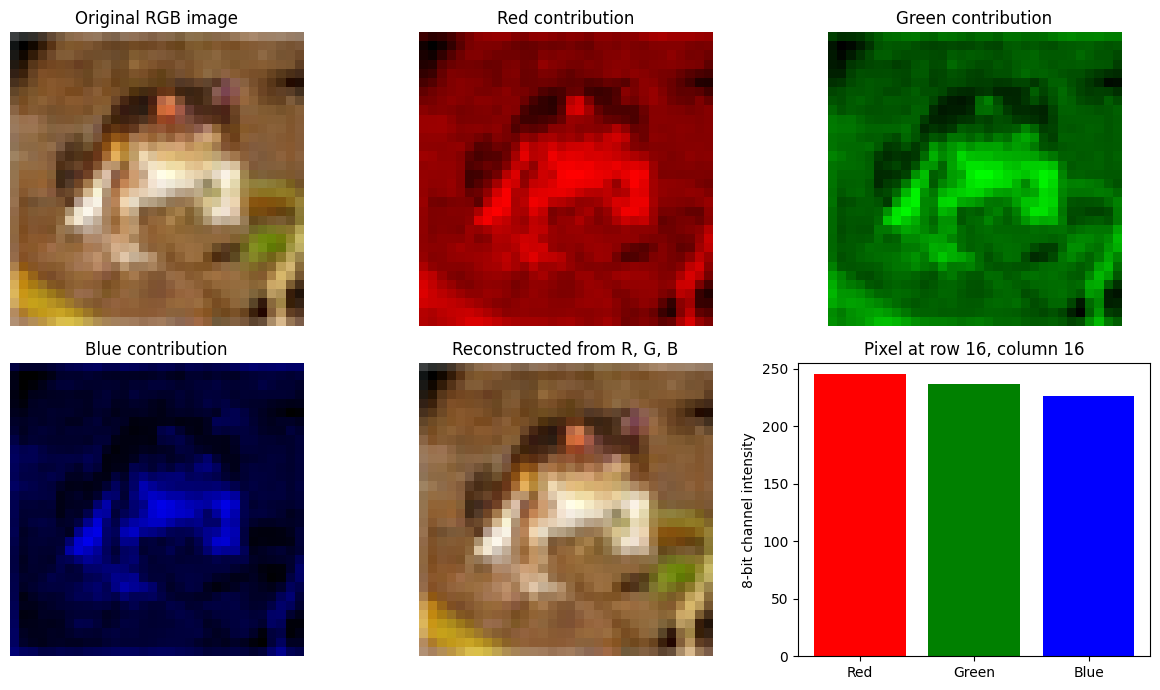

Exact reconstruction: True


In [5]:
import numpy as np
import matplotlib.pyplot as plt

image = x_train_full[0]
channels = [image[:, :, k] for k in range(3)]
colors = ["Red", "Green", "Blue"]
reassembled = np.stack(channels, axis=-1)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes[0, 0].imshow(image)
axes[0, 0].set_title("Original RGB image")

for channel_index in range(3):
    contribution = np.zeros_like(image)
    contribution[:, :, channel_index] = channels[channel_index]
    ax = axes.flat[channel_index + 1]
    ax.imshow(contribution)
    ax.set_title(f"{colors[channel_index]} contribution")

axes[1, 1].imshow(reassembled)
axes[1, 1].set_title("Reconstructed from R, G, B")

pixel_values = image[16, 16]
axes[1, 2].bar(colors, pixel_values, color=["red", "green", "blue"])
axes[1, 2].set_ylim(0, 255)
axes[1, 2].set_ylabel("8-bit channel intensity")
axes[1, 2].set_title("Pixel at row 16, column 16")

for ax in axes.flat[:5]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Exact reconstruction:", np.array_equal(image, reassembled))

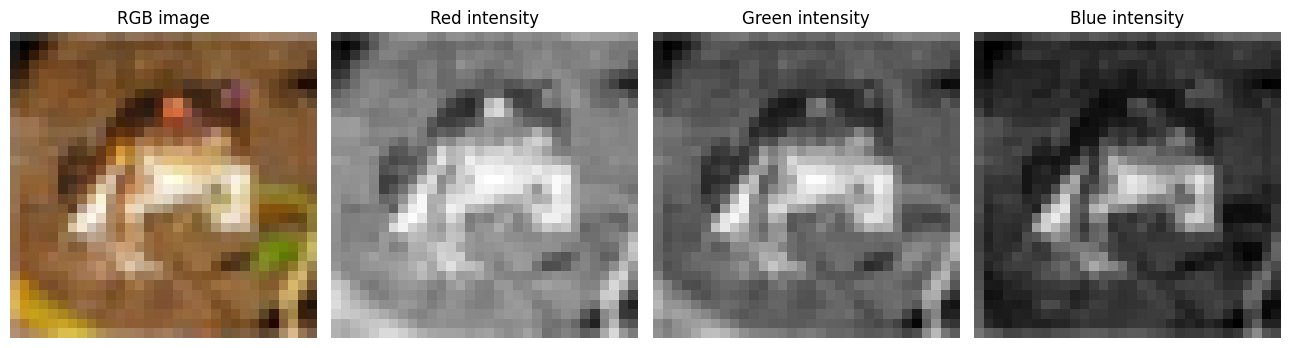

In [6]:
import matplotlib.pyplot as plt

image = x_train_full[0]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
axes[0].imshow(image)
axes[0].set_title("RGB image")

for index, label in enumerate(["Red intensity", "Green intensity", "Blue intensity"]):
    axes[index + 1].imshow(image[:, :, index], cmap="gray", vmin=0, vmax=255)
    axes[index + 1].set_title(label)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

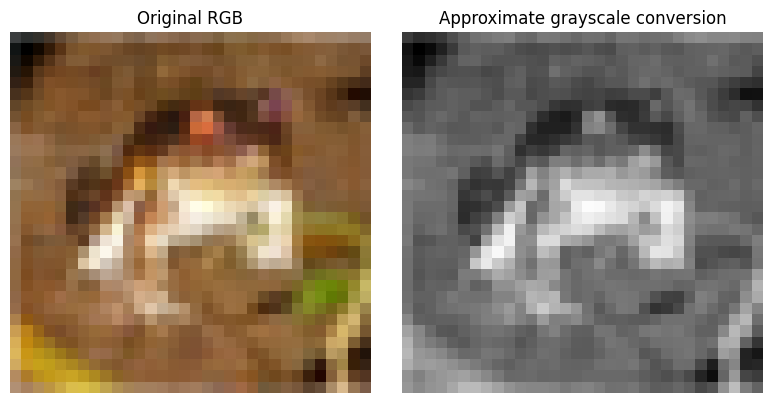

Original shape: (32, 32, 3)
Grayscale shape: (32, 32)


In [7]:
import numpy as np
import matplotlib.pyplot as plt

rgb = x_train_full[0].astype("float32")
grayscale = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb.astype("uint8"))
axes[0].set_title("Original RGB")
axes[1].imshow(grayscale, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Approximate grayscale conversion")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Original shape:", rgb.shape)
print("Grayscale shape:", grayscale.shape)

In [8]:
one_image = x_train_full[0]
small_batch = x_train_full[:64]
image_tensor = tf.convert_to_tensor(one_image)
batch_tensor = tf.convert_to_tensor(small_batch)

print("NumPy image shape/rank:", one_image.shape, one_image.ndim)
print("TensorFlow image shape/rank:", image_tensor.shape, image_tensor.ndim)
print("TensorFlow batch shape/rank:", batch_tensor.shape, batch_tensor.ndim)
print("TensorFlow dtype:", batch_tensor.dtype)

NumPy image shape/rank: (32, 32, 3) 3
TensorFlow image shape/rank: (32, 32, 3) 3
TensorFlow batch shape/rank: (64, 32, 32, 3) 4
TensorFlow dtype: <dtype: 'uint8'>


In [9]:
weight = tf.Variable(2.0)
input_value = tf.constant(3.0)
target = tf.constant(4.0)
learning_rate_demo = 0.1

with tf.GradientTape() as tape:
    prediction = weight * input_value
    loss_demo = 0.5 * tf.square(prediction - target)

gradient_demo = tape.gradient(loss_demo, weight)
print("Prediction before update:", float(prediction.numpy()))
print("Loss before update:", float(loss_demo.numpy()))
print("Gradient:", float(gradient_demo.numpy()))

# This explicit assignment is the optimizer-style update step.
weight.assign_sub(learning_rate_demo * gradient_demo)
new_prediction = weight * input_value
new_loss = 0.5 * tf.square(new_prediction - target)
print("Weight after update:", float(weight.numpy()))
print("Prediction after update:", float(new_prediction.numpy()))
print("Loss after update:", float(new_loss.numpy()))

Prediction before update: 6.0
Loss before update: 2.0
Gradient: 6.0
Weight after update: 1.399999976158142
Prediction after update: 4.199999809265137
Loss after update: 0.01999996230006218


In [10]:
x_train = x_train_full[:40000].astype("float32") / 255.0
y_train = y_train_full[:40000]
x_val = x_train_full[40000:].astype("float32") / 255.0
y_val = y_train_full[40000:]
x_test = x_test_raw.astype("float32") / 255.0

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Training data range:", x_train.min(), x_train.max())

Training: (40000, 32, 32, 3) (40000,)
Validation: (10000, 32, 32, 3) (10000,)
Test: (10000, 32, 32, 3) (10000,)
Training data range: 0.0 1.0


In [11]:
def build_cifar_model():
    inputs = keras.Input(shape=(32, 32, 3), name="RGB_image")
    h = layers.Flatten(name="Flatten")(inputs)
    h = layers.Dense(256, activation="relu", name="Hidden_1")(h)
    h = layers.Dense(256, activation="relu", name="Hidden_2")(h)
    outputs = layers.Dense(10, activation="softmax", name="Class_probabilities")(h)
    return keras.Model(inputs=inputs, outputs=outputs, name="CIFAR10_DNN")

keras.utils.set_random_seed(42)
model = build_cifar_model()
model.summary()

Model: "CIFAR10_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ RGB_image (InputLayer)          │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Class_probabilities (Dense)     │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,050 (3.26 MB)

 Trainable params: 855,050 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

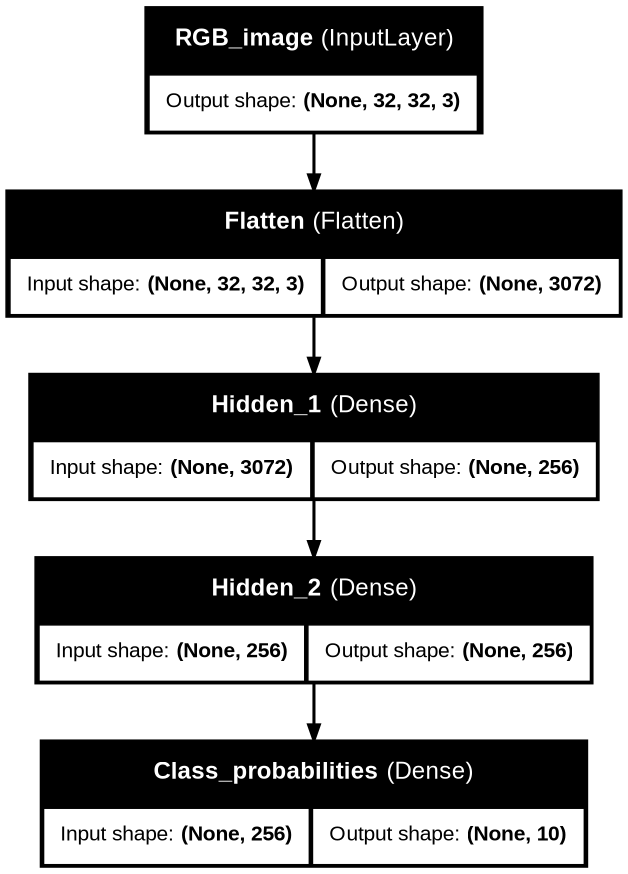

In [12]:
from IPython.display import Image, display

keras.utils.plot_model(
    model,
    to_file="cifar10_dnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=110,
)
display(Image(filename="cifar10_dnn_architecture.png"))

In [13]:
example_probabilities = np.array(
    [0.03, 0.02, 0.02, 0.72, 0.03, 0.04, 0.03, 0.03, 0.04, 0.04],
    dtype="float64",
)
example_sparse_label = 3
example_one_hot_label = np.eye(10)[example_sparse_label]

sparse_loss = -np.log(example_probabilities[example_sparse_label])
one_hot_loss = -np.sum(example_one_hot_label * np.log(example_probabilities))
print("Sparse class ID:", example_sparse_label)
print("One-hot target:", example_one_hot_label.astype(int).tolist())
print("Sparse loss:", round(float(sparse_loss), 6))
print("One-hot loss:", round(float(one_hot_loss), 6))
print("Equivalent:", np.isclose(sparse_loss, one_hot_loss))

Sparse class ID: 3
One-hot target: [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
Sparse loss: 0.328504
One-hot loss: 0.328504
Equivalent: True


In [14]:
batch_size = 64
max_epochs = 20

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [15]:
baseline_history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    epochs=max_epochs,
    verbose=2,
)

print("Completed baseline epochs:", len(baseline_history.history["loss"]))
print("Final training loss:", baseline_history.history["loss"][-1])
print("Final validation loss:", baseline_history.history["val_loss"][-1])

Epoch 1/20
625/625 - 12s - 19ms/step - accuracy: 0.3175 - loss: 1.8887 - val_accuracy: 0.3761 - val_loss: 1.7382
Epoch 2/20
625/625 - 10s - 16ms/step - accuracy: 0.3901 - loss: 1.7008 - val_accuracy: 0.4094 - val_loss: 1.6506
Epoch 3/20
625/625 - 11s - 17ms/step - accuracy: 0.4254 - loss: 1.6134 - val_accuracy: 0.4226 - val_loss: 1.6149
Epoch 4/20
625/625 - 11s - 17ms/step - accuracy: 0.4442 - loss: 1.5570 - val_accuracy: 0.4435 - val_loss: 1.5739
Epoch 5/20
625/625 - 12s - 19ms/step - accuracy: 0.4586 - loss: 1.5192 - val_accuracy: 0.4496 - val_loss: 1.5549
Epoch 6/20
625/625 - 19s - 31ms/step - accuracy: 0.4712 - loss: 1.4839 - val_accuracy: 0.4554 - val_loss: 1.5451
Epoch 7/20
625/625 - 11s - 17ms/step - accuracy: 0.4800 - loss: 1.4540 - val_accuracy: 0.4481 - val_loss: 1.5483
Epoch 8/20
625/625 - 11s - 17ms/step - accuracy: 0.4887 - loss: 1.4258 - val_accuracy: 0.4553 - val_loss: 1.5600
Epoch 9/20
625/625 - 13s - 21ms/step - accuracy: 0.4965 - loss: 1.4079 - val_accuracy: 0.4492 - 

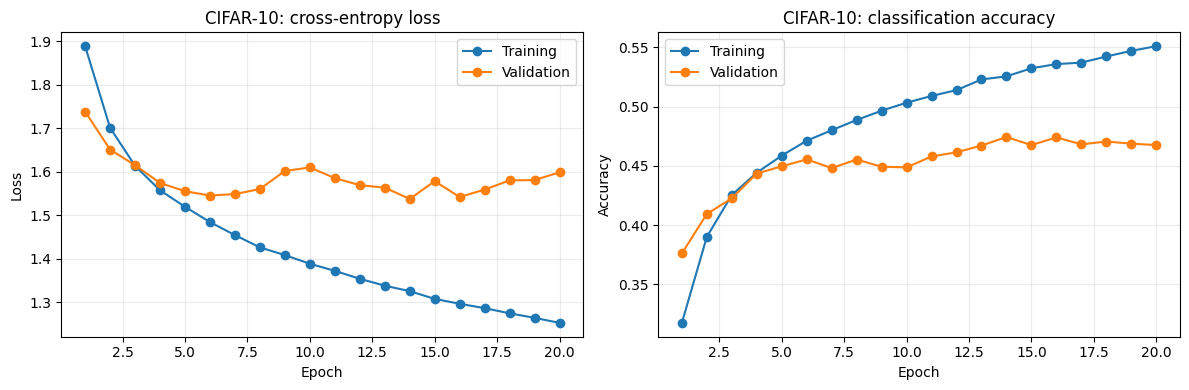

In [16]:
import numpy as np
import matplotlib.pyplot as plt

history_values = baseline_history.history
epoch_numbers = np.arange(1, len(history_values["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoch_numbers, history_values["loss"], marker="o", label="Training")
axes[0].plot(epoch_numbers, history_values["val_loss"], marker="o", label="Validation")
axes[0].set_title("CIFAR-10: cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epoch_numbers, history_values["accuracy"], marker="o", label="Training")
axes[1].plot(epoch_numbers, history_values["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("CIFAR-10: classification accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [17]:
keras.utils.set_random_seed(42)
early_model = build_cifar_model()
early_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

early_history = early_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    epochs=max_epochs,
    callbacks=[early_stop],
    verbose=2,
)

best_epoch = int(np.argmin(early_history.history["val_loss"])) + 1
last_epoch = len(early_history.history["loss"])
print("Best validation-loss epoch:", best_epoch)
print("Last completed epoch:", last_epoch)
print("Best recorded validation loss:", min(early_history.history["val_loss"]))

Epoch 1/20
625/625 - 13s - 20ms/step - accuracy: 0.3175 - loss: 1.8887 - val_accuracy: 0.3761 - val_loss: 1.7382
Epoch 2/20
625/625 - 21s - 33ms/step - accuracy: 0.3901 - loss: 1.7008 - val_accuracy: 0.4094 - val_loss: 1.6506
Epoch 3/20
625/625 - 12s - 19ms/step - accuracy: 0.4254 - loss: 1.6134 - val_accuracy: 0.4226 - val_loss: 1.6149
Epoch 4/20
625/625 - 21s - 33ms/step - accuracy: 0.4442 - loss: 1.5570 - val_accuracy: 0.4435 - val_loss: 1.5739
Epoch 5/20
625/625 - 10s - 16ms/step - accuracy: 0.4586 - loss: 1.5192 - val_accuracy: 0.4496 - val_loss: 1.5549
Epoch 6/20
625/625 - 11s - 17ms/step - accuracy: 0.4712 - loss: 1.4839 - val_accuracy: 0.4554 - val_loss: 1.5451
Epoch 7/20
625/625 - 11s - 18ms/step - accuracy: 0.4800 - loss: 1.4540 - val_accuracy: 0.4481 - val_loss: 1.5483
Epoch 8/20
625/625 - 11s - 18ms/step - accuracy: 0.4887 - loss: 1.4258 - val_accuracy: 0.4553 - val_loss: 1.5600
Epoch 9/20
625/625 - 12s - 19ms/step - accuracy: 0.4965 - loss: 1.4079 - val_accuracy: 0.4492 - 

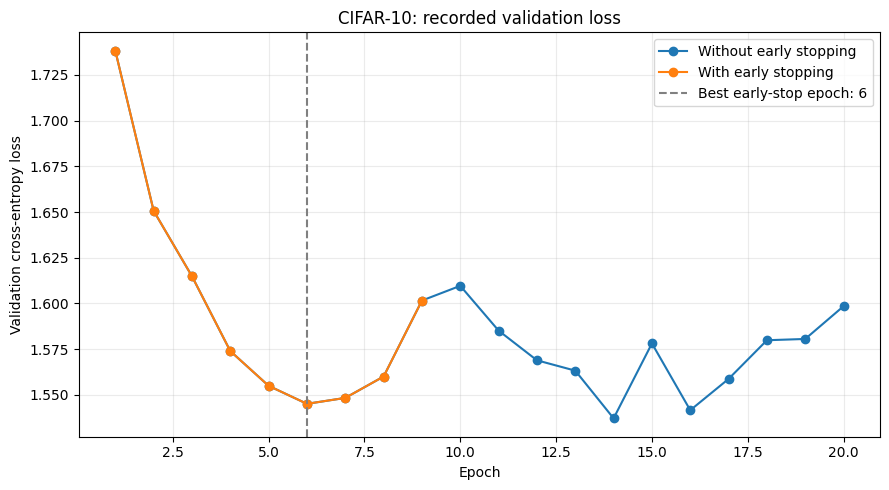

In [18]:
import numpy as np
import matplotlib.pyplot as plt

baseline_epochs = np.arange(1, len(baseline_history.history["val_loss"]) + 1)
early_epochs = np.arange(1, len(early_history.history["val_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(baseline_epochs, baseline_history.history["val_loss"],
         marker="o", label="Without early stopping")
plt.plot(early_epochs, early_history.history["val_loss"],
         marker="o", label="With early stopping")
plt.axvline(best_epoch, color="gray", linestyle="--",
            label=f"Best early-stop epoch: {best_epoch}")
plt.title("CIFAR-10: recorded validation loss")
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [19]:
test_loss, test_accuracy = early_model.evaluate(x_test, y_test, verbose=0)
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.2%}")

sample_index = 12
sample_probabilities = early_model.predict(
    x_test[sample_index:sample_index + 1], verbose=0
)[0]
predicted_class = int(np.argmax(sample_probabilities))
print("True class:", class_names[int(y_test[sample_index])])
print("Predicted class:", class_names[predicted_class])
print("Sum of probabilities:", float(sample_probabilities.sum()))

Final test loss: 1.5135
Final test accuracy: 46.70%
True class: dog
Predicted class: frog
Sum of probabilities: 1.0


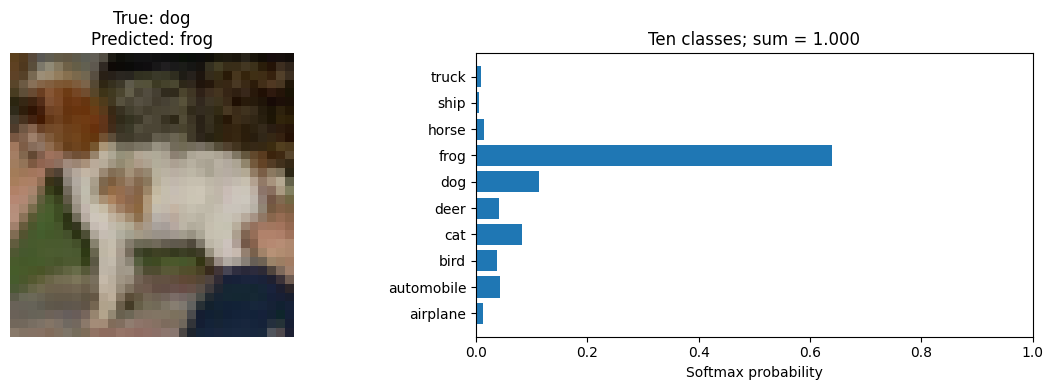

In [20]:
import numpy as np
import matplotlib.pyplot as plt

idx = 12
image = x_test[idx]
true_id = int(y_test[idx])
probs = early_model.predict(image[None, ...], verbose=0)[0]
pred_id = int(np.argmax(probs))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set_title(f"True: {class_names[true_id]}\nPredicted: {class_names[pred_id]}")
axes[0].axis("off")

axes[1].barh(class_names, probs)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Softmax probability")
axes[1].set_title(f"Ten classes; sum = {probs.sum():.3f}")
plt.tight_layout()
plt.show()

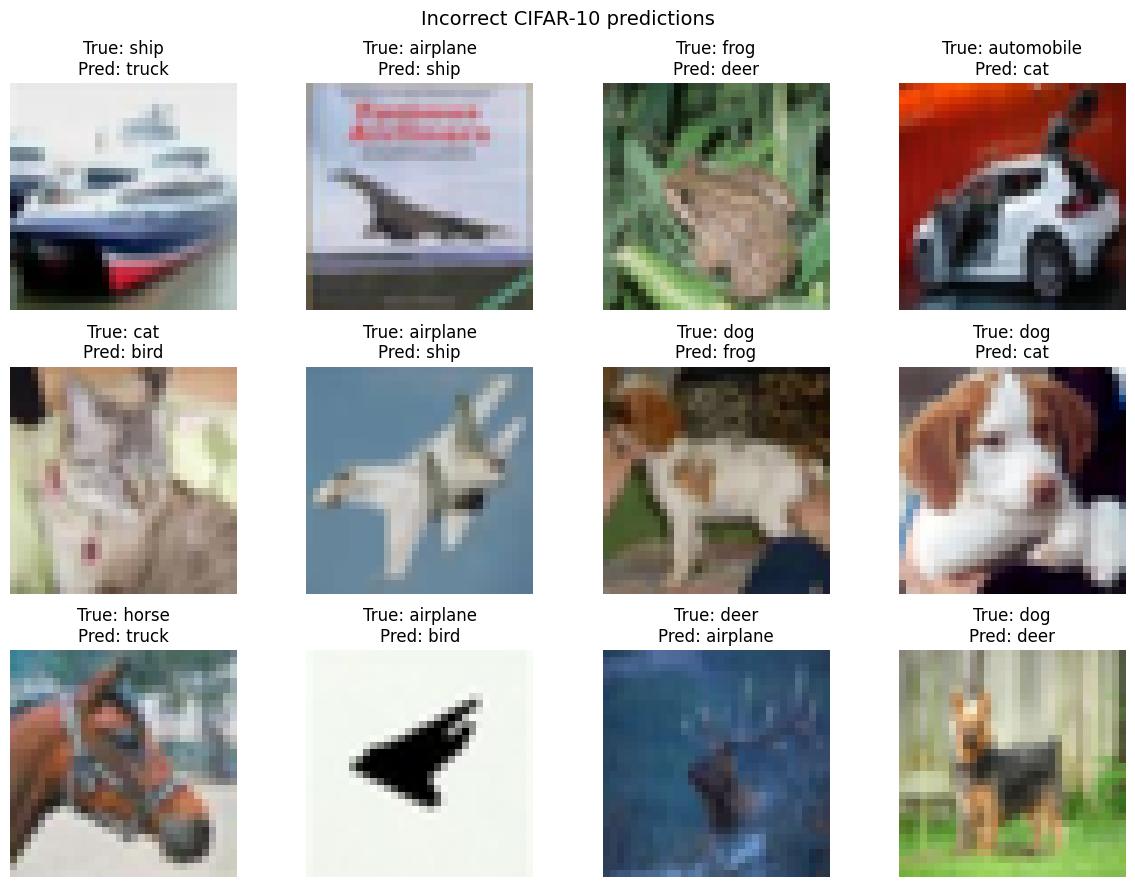

In [21]:
import numpy as np
import matplotlib.pyplot as plt

subset_size = 1000
subset_probabilities = early_model.predict(x_test[:subset_size], verbose=0)
subset_predictions = np.argmax(subset_probabilities, axis=1)
wrong_indices = np.flatnonzero(subset_predictions != y_test[:subset_size])[:12]

if len(wrong_indices) == 0:
    print("No incorrect predictions in the inspected subset.")
else:
    cols = 4
    rows = int(np.ceil(len(wrong_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, wrong_indices):
        ax.imshow(x_test[idx])
        ax.set_title(
            f"True: {class_names[int(y_test[idx])]}\n"
            f"Pred: {class_names[int(subset_predictions[idx])]}"
        )
        ax.axis("off")
    fig.suptitle("Incorrect CIFAR-10 predictions", fontsize=14)
    plt.tight_layout()
    plt.show()